[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/learn-python-from-scratch-to-advanced/blob/main/notebooks/02-data-science/11_eda-kpis.ipynb)

*Python for Data Science · Notebook 11 of 12*

# EDA, Business KPIs & Storytelling

Explore a new dataset systematically, turn Excel habits (VLOOKUP, pivot tables, SUMIFS, IF) into pandas, and compute the metrics businesses run on: funnels, cohorts and retention, churn, ARPU, LTV, growth, Pareto shares and what drove a change.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** EDA is a doctor's check-up for a dataset, and KPIs are its vital signs: take them the same way every time, and investigate when one moves.

**What interviewers really test here:** First steps with a new dataset, defining KPIs precisely, funnels, cohorts and churn, explaining a metric drop, and charts that make one point.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. EDA: a checklist for any new dataset *(Basics)*
- [ ] 2. From Excel to pandas *(Core)*
- [ ] 3. The KPIs every analyst should know *(Core)*
- [ ] 4. Funnels, cohorts and churn *(Core)*
- [ ] 5. Explaining a change, and telling the story *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### What EDA is for

- **Understand the grain**: what one row represents. Most analysis bugs come from getting this wrong (counting order lines as orders).
- **Find data problems** before they become wrong conclusions: gaps, duplicates, impossible values, units.
- **Form hypotheses** to test properly later; EDA alone shows associations, not causes.

### Choosing a chart

| Message | Chart |
| --- | --- |
| Change over time | line |
| Compare categories | sorted horizontal bar |
| Distribution | histogram, box plot |
| Relationship | scatter (add a trend line) |
| Part of a whole | stacked bar; a pie only for 2–3 parts |
| Cohorts, two categories | heat map |
| One headline number | a big number with its change vs last period |

### Good KPI definitions

A KPI needs: a **name**, an exact **formula** (numerator and denominator), the **grain and time window**, **filters** (test accounts, refunds), the **owner**, and the **target**. Pair every KPI with a counter-metric so it can't be gamed: conversion with refund rate, speed with error rate.



A **North Star metric** captures the value customers get (e.g. weekly orders delivered on time). Input metrics are the levers that move it.

---
# Part 2: Lessons, step by step

## Lesson 1: EDA: a checklist for any new dataset

*Level: Basics*

**Exploratory Data Analysis** is getting to know a dataset before you trust it. Do it in the same order every time:




1. **Shape and grain**: how many rows, and what does one row mean (one order? one user per day?). `df.shape`, `df.head()`.
2. **Types and gaps**: `df.info()`, `df.isna().sum()`, `df.nunique()`. Is a date stored as text? Is an ID column numeric by accident?
3. **Univariate**: each column alone. Numbers: `describe()`, a histogram, skewness. Categories: `value_counts()`.
4. **Bivariate**: pairs. Number vs number: scatter and correlation. Category vs number: groupby and box plots. Category vs category: crosstab.
5. **Sanity checks**: duplicates, impossible values (negative ages), totals that should match a known figure.
6. **Write down questions and findings** as you go; EDA ends with a short list of facts and open questions, not 50 charts.



Skewed money data (most orders small, a few huge) is the norm: report the median with the mean, and try a log scale on charts.

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q12](#q12), [Q13](#q13), [Q2](#q2), [Q11](#q11). Try one now, or carry on and do them in Part 3.

## Lesson 2: From Excel to pandas

*Level: Core*

Most business teams live in Excel. Every Excel habit has a pandas twin that is repeatable and handles millions of rows:



| Excel | pandas |
| --- | --- |
| VLOOKUP / XLOOKUP | `df.merge(lookup, on="key", how="left")` or `df.key.map(dict)` |
| Pivot table | `df.pivot_table(index=…, columns=…, values=…, aggfunc="sum", margins=True)` |
| SUMIFS / COUNTIFS | `df.loc[mask1 & mask2, "v"].sum()` |
| Nested IF | `np.select(conditions, choices, default=…)` |
| FREQUENCY / bins | `pd.cut(…).value_counts(sort=False)` |
| Filters, sort | `df.query(…)`, `sort_values` |
| Conditional formatting | `df.style.background_gradient()` |
| Read / write sheets | `pd.read_excel`, `df.to_excel` (needs openpyxl) |

**✏️ Your turn:** you now have what you need for [Q3](#q3), [Q14](#q14), [Q4](#q4), [Q5](#q5). Try one now, or carry on and do them in Part 3.

## Lesson 3: The KPIs every analyst should know

*Level: Core*

| KPI | Formula | Answers |
| --- | --- | --- |
| Conversion rate | users who did X ÷ users who could | is the funnel working? |
| AOV | revenue ÷ orders | how big is a typical basket? |
| ARPU / ARPPU | revenue ÷ all users / paying users | how much is a user worth per month? |
| Retention / churn | share still active / gone next period | do people stay? |
| DAU / MAU | average daily ÷ monthly actives | how habit-forming is the product? |
| LTV | ARPU × margin ÷ churn | how much can we pay to acquire a user? |
| CAC | marketing spend ÷ new customers | LTV/CAC above ~3 is healthy |
| Growth | (this − last) ÷ last | are we growing? |



Define every KPI precisely before computing it: which users count, which time zone, are refunds removed? Two teams with different definitions will "disagree" about the same data.

**✏️ Your turn:** you now have what you need for [Q6](#q6), [Q8](#q8), [Q9](#q9), [Q7](#q7), [Q19](#q19). Try one now, or carry on and do them in Part 3.

## Lesson 4: Funnels, cohorts and churn

*Level: Core*

A **funnel** counts users at each step (visit → cart → buy) and shows where they drop off. The step with the biggest drop is where to dig.



A **cohort** is a group that started at the same time (signed up in January). A **retention table** has cohorts as rows and months since start as columns; each cell is the share still active. Reading down a column compares cohorts — are newer users sticking better? Reading across a row shows how one cohort decays.



**Churn** is the share of last period's active users who didn't come back. Monthly churn of 5% means an average lifetime of about 1 / 0.05 = 20 months.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

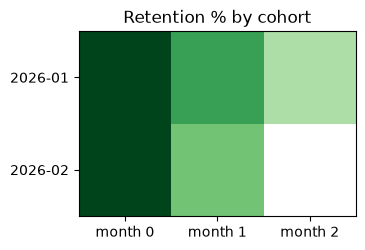

In [2]:
ORDERS = pd.DataFrame({
    "user": ["u1", "u2", "u3", "u1", "u3", "u4", "u5", "u1", "u5"],
    "month": ["2026-01"] * 3 + ["2026-02"] * 4 + ["2026-03"] * 2,
    "segment": ["Retail", "Retail", "Business", "Retail", "Business", "Retail", "Business", "Retail", "Business"],
    "amount": [120.0, 80, 400, 60, 650, 90, 300, 110, 150],
})


def cohort_heatmap():
    df = ORDERS.copy()
    p = pd.PeriodIndex(df["month"], freq="M")
    df["cohort"] = p.to_series(index=df.index).groupby(df["user"]).transform("min")
    df["offset"] = (p - pd.PeriodIndex(df["cohort"], freq="M")).map(lambda d: d.n)
    t = df.pivot_table(index="cohort", columns="offset", values="user", aggfunc="nunique")
    t = t.div(t[0], axis=0) * 100
    fig, ax = plt.subplots(figsize=(4.5, 2.4))
    ax.imshow(t.to_numpy(dtype=float), cmap="Greens", vmin=0, vmax=100)
    ax.set_xticks(range(len(t.columns)), [f"month {c}" for c in t.columns])
    ax.set_yticks(range(len(t.index)), [str(c) for c in t.index])
    ax.set_title("Retention % by cohort")


cohort_heatmap()

**✏️ Your turn:** you now have what you need for [Q15](#q15), [Q20](#q20), [Q16](#q16). Try one now, or carry on and do them in Part 3.

## Lesson 5: Explaining a change, and telling the story

*Level: Advanced*

"Revenue fell 76% in March — why?" Break the change into parts: by segment, by region, by new vs returning users, and by **volume × price** (fewer orders, or smaller ones?). Sort the parts by absolute change; usually one or two explain most of it. Check the boring causes first: a missing day of data, a tracking change, a holiday.



**Data storytelling** turns analysis into a decision:




1. **Lead with the answer**: "March revenue fell because two Business accounts didn't reorder."
2. **One chart, one message**, and the title states the message, not "Revenue by month".
3. **Make it easy to read**: sort bars, group small categories into "Other", label directly instead of a legend, highlight the one bar that matters and grey the rest.
4. **Say what to do next** and how sure you are.



**Dashboards** (Power BI, Tableau, Looker, or Python tools like Streamlit) show the same KPIs every day. Their skills are the same as here — clean data, precise KPI definitions, the right chart — plus point-and-click building. The tools themselves are best learned hands-on with their free desktop versions; everything they compute, you can now compute in pandas.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

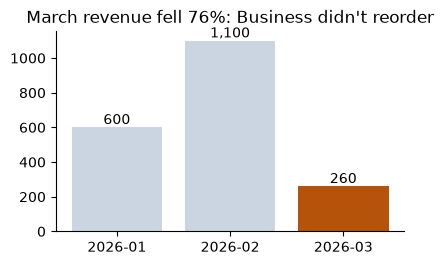

In [3]:
ORDERS = pd.DataFrame({
    "user": ["u1", "u2", "u3", "u1", "u3", "u4", "u5", "u1", "u5"],
    "month": ["2026-01"] * 3 + ["2026-02"] * 4 + ["2026-03"] * 2,
    "segment": ["Retail", "Retail", "Business", "Retail", "Business", "Retail", "Business", "Retail", "Business"],
    "amount": [120.0, 80, 400, 60, 650, 90, 300, 110, 150],
})


def story_chart():
    rev = ORDERS.groupby("month")["amount"].sum()
    colors = ["#cbd5e1"] * len(rev)
    colors[-1] = "#b45309"
    fig, ax = plt.subplots(figsize=(4.5, 2.6))
    ax.bar(rev.index, rev.values, color=colors)
    for x, v in zip(rev.index, rev.values):
        ax.text(x, v, f"{v:,.0f}", ha="center", va="bottom")
    ax.set_title("March revenue fell 76%: Business didn't reorder")
    ax.spines[["top", "right"]].set_visible(False)


story_chart()

**✏️ Your turn:** you now have what you need for [Q18](#q18), [Q17](#q17), [Q10](#q10). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

**▶ Run this cell before the questions.** It sets up the data and tools they share.

In [4]:
import math


<a id="q1"></a>
### Q1. Profile a New Dataset

🟢 Warm-up · *First look*

For each column of `rows` (a list of dicts, None = missing) return `(missing count, distinct non-missing values)`, keyed by column.

**Examples**

- `rows = [{'a': 1, 'b': 'x'}, {'a': None, 'b': 'x'}, {'a': 3, 'b': None}, {'a': 1, 'b': 'y'}]` → `{'a': (1, 2), 'b': (1, 2)}`

In [ ]:
def profile(rows):
    """
    For each column of rows (a list of dicts, None = missing) return (missing
    count, distinct non-missing values), keyed by column.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(profile, [
    (([{'a': 1, 'b': 'x'}, {'a': None, 'b': 'x'}, {'a': 3, 'b': None}, {'a': 1, 'b': 'y'}],), {'a': (1, 2), 'b': (1, 2)}),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop over columns and rows, counting Nones and collecting a set.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`df.isna().sum()` and `df.nunique()` — the first two lines of every EDA.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Loop over columns and rows, counting Nones and collecting a set.

```python
def profile(rows):
    out = {}
    for col in rows[0]:
        values = [r[col] for r in rows]
        missing = sum(v is None for v in values)
        out[col] = (missing, len({v for v in values if v is not None}))
    return out
```

**Cost:** O(rc) time, O(rc) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `df.isna().sum()` and `df.nunique()` — the first two lines of every EDA.

```python
def profile(rows):
    df = pd.DataFrame(rows)
    return {c: (int(df[c].isna().sum()), int(df[c].nunique())) for c in df.columns}
```

**Cost:** O(rc) time, O(rc) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop over columns and rows, counting Nones and collecting a set. That costs O(rc) time and O(rc) space."

"I can do better: `df.isna().sum()` and `df.nunique()` — the first two lines of every EDA. That's O(rc) time and O(rc) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/eda-kpis/profile-a-new-dataset)

<a id="q2"></a>
### Q2. Segment Summary

🟢 Warm-up · *Category vs number*

Return, per segment (sorted), `(orders, total, average order value)`, rounded to 2.

**Examples**

- `orders = [{'user': 'u1', 'month': '2026-01', 'segment': 'Retail', 'amount': 120.0}, {'user': 'u2', 'month': '2026-01', 'segment': 'Retail', 'amount': 80.0}, {'user': 'u3', 'month': '2026-01', 'segment': 'Business', 'amount': 400.0}, {'user': 'u1', 'month': '2026-02', 'segment': 'Retail', 'amount': 60.0}, {'user': 'u3', 'month': '2026-02', 'segment': 'Business', 'amount': 650.0}, {'user': 'u4', 'month': '2026-02', 'segment': 'Retail', 'amount': 90.0}, {'user': 'u5', 'month': '2026-02', 'segment': 'Business', 'amount': 300.0}, {'user': 'u1', 'month': '2026-03', 'segment': 'Retail', 'amount': 110.0}, {'user': 'u5', 'month': '2026-03', 'segment': 'Business', 'amount': 150.0}]` → `{'Business': (4, 1500.0, 375.0), 'Retail': (5, 460.0, 92.0)}`

In [ ]:
def segment_summary(orders):
    """
    Return, per segment (sorted), (orders, total, average order value), rounded
    to 2.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(segment_summary, [
    (([{'user': 'u1', 'month': '2026-01', 'segment': 'Retail', 'amount': 120.0}, {'user': 'u2', 'month': '2026-01', 'segment': 'Retail', 'amount': 80.0}, {'user': 'u3', 'month': '2026-01', 'segment': 'Business', 'amount': 400.0}, {'user': 'u1', 'month': '2026-02', 'segment': 'Retail', 'amount': 60.0}, {'user': 'u3', 'month': '2026-02', 'segment': 'Business', 'amount': 650.0}, {'user': 'u4', 'month': '2026-02', 'segment': 'Retail', 'amount': 90.0}, {'user': 'u5', 'month': '2026-02', 'segment': 'Business', 'amount': 300.0}, {'user': 'u1', 'month': '2026-03', 'segment': 'Retail', 'amount': 110.0}, {'user': 'u5', 'month': '2026-03', 'segment': 'Business', 'amount': 150.0}],), {'Business': (4, 1500.0, 375.0), 'Retail': (5, 460.0, 92.0)}),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Dicts of totals and counts.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`groupby('segment')['amount'].agg(['count', 'sum', 'mean'])`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Dicts of totals and counts.

```python
def segment_summary(orders):
    total, count = {}, {}
    for o in orders:
        total[o["segment"]] = total.get(o["segment"], 0) + o["amount"]
        count[o["segment"]] = count.get(o["segment"], 0) + 1
    return {s: (count[s], round(total[s], 2), round(total[s] / count[s], 2)) for s in sorted(total)}
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `groupby('segment')['amount'].agg(['count', 'sum', 'mean'])`.

```python
def segment_summary(orders):
    g = pd.DataFrame(orders).groupby("segment")["amount"].agg(["count", "sum", "mean"]).round(2)
    return {s: (int(r["count"]), r["sum"], r["mean"]) for s, r in g.iterrows()}
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Dicts of totals and counts. That costs O(n) time and O(k) space."

"I can do better: `groupby('segment')['amount'].agg(['count', 'sum', 'mean'])`. That's O(n) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/eda-kpis/segment-summary)

<a id="q3"></a>
### Q3. VLOOKUP in pandas

🟢 Warm-up · *Left merge*

Attach each order's region by looking up its `store` in `stores` (store → region). Unknown stores get None. Return the list of regions in order.

**Examples**

- `orders = [{'id': 1, 'store': 'S1'}, {'id': 2, 'store': 'S9'}, {'id': 3, 'store': 'S2'}], stores = {'S1': 'North', 'S2': 'South'}` → `['North', None, 'South']`

In [ ]:
def lookup_region(orders, stores):
    """
    Attach each order's region by looking up its store in stores (store →
    region). Unknown stores get None. Return the list of regions in order.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(lookup_region, [
    (([{'id': 1, 'store': 'S1'}, {'id': 2, 'store': 'S9'}, {'id': 3, 'store': 'S2'}], {'S1': 'North', 'S2': 'South'}), ['North', None, 'South']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

`dict.get` for each row — exactly what VLOOKUP does.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`merge(how='left')` keeps every order, like VLOOKUP with IFERROR.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** `dict.get` for each row — exactly what VLOOKUP does.

```python
def lookup_region(orders, stores):
    return [stores.get(o["store"]) for o in orders]
```

**Cost:** O(n) time, O(m) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `merge(how='left')` keeps every order, like VLOOKUP with IFERROR.

```python
def lookup_region(orders, stores):
    left = pd.DataFrame(orders)
    right = pd.DataFrame(list(stores.items()), columns=["store", "region"])
    merged = left.merge(right, on="store", how="left")
    return [None if pd.isna(r) else r for r in merged["region"]]
```

**Cost:** O(n + m) time, O(n + m) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: `dict.get` for each row — exactly what VLOOKUP does. That costs O(n) time and O(m) space."

"I can do better: `merge(how='left')` keeps every order, like VLOOKUP with IFERROR. That's O(n + m) time and O(n + m) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/eda-kpis/vlookup-in-pandas)

<a id="q4"></a>
### Q4. SUMIFS

🟢 Warm-up · *Sum with several conditions*

Return total amount for `segment` in months from `start` to `end` (inclusive, 'YYYY-MM' text).

**Examples**

- `orders = [{'user': 'u1', 'month': '2026-01', 'segment': 'Retail', 'amount': 120.0}, {'user': 'u2', 'month': '2026-01', 'segment': 'Retail', 'amount': 80.0}, {'user': 'u3', 'month': '2026-01', 'segment': 'Business', 'amount': 400.0}, {'user': 'u1', 'month': '2026-02', 'segment': 'Retail', 'amount': 60.0}, {'user': 'u3', 'month': '2026-02', 'segment': 'Business', 'amount': 650.0}, {'user': 'u4', 'month': '2026-02', 'segment': 'Retail', 'amount': 90.0}, {'user': 'u5', 'month': '2026-02', 'segment': 'Business', 'amount': 300.0}, {'user': 'u1', 'month': '2026-03', 'segment': 'Retail', 'amount': 110.0}, {'user': 'u5', 'month': '2026-03', 'segment': 'Business', 'amount': 150.0}], segment = 'Retail', start = '2026-02', end = '2026-03'` → `260.0`
- `orders = [{'user': 'u1', 'month': '2026-01', 'segment': 'Retail', 'amount': 120.0}, {'user': 'u2', 'month': '2026-01', 'segment': 'Retail', 'amount': 80.0}, {'user': 'u3', 'month': '2026-01', 'segment': 'Business', 'amount': 400.0}, {'user': 'u1', 'month': '2026-02', 'segment': 'Retail', 'amount': 60.0}, {'user': 'u3', 'month': '2026-02', 'segment': 'Business', 'amount': 650.0}, {'user': 'u4', 'month': '2026-02', 'segment': 'Retail', 'amount': 90.0}, {'user': 'u5', 'month': '2026-02', 'segment': 'Business', 'amount': 300.0}, {'user': 'u1', 'month': '2026-03', 'segment': 'Retail', 'amount': 110.0}, {'user': 'u5', 'month': '2026-03', 'segment': 'Business', 'amount': 150.0}], segment = 'Business', start = '2026-01', end = '2026-01'` → `400.0`

In [ ]:
def sumifs(orders, segment, start, end):
    """
    Return total amount for segment in months from start to end (inclusive,
    'YYYY-MM' text).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(sumifs, [
    (([{'user': 'u1', 'month': '2026-01', 'segment': 'Retail', 'amount': 120.0}, {'user': 'u2', 'month': '2026-01', 'segment': 'Retail', 'amount': 80.0}, {'user': 'u3', 'month': '2026-01', 'segment': 'Business', 'amount': 400.0}, {'user': 'u1', 'month': '2026-02', 'segment': 'Retail', 'amount': 60.0}, {'user': 'u3', 'month': '2026-02', 'segment': 'Business', 'amount': 650.0}, {'user': 'u4', 'month': '2026-02', 'segment': 'Retail', 'amount': 90.0}, {'user': 'u5', 'month': '2026-02', 'segment': 'Business', 'amount': 300.0}, {'user': 'u1', 'month': '2026-03', 'segment': 'Retail', 'amount': 110.0}, {'user': 'u5', 'month': '2026-03', 'segment': 'Business', 'amount': 150.0}], 'Retail', '2026-02', '2026-03'), 260.0),
    (([{'user': 'u1', 'month': '2026-01', 'segment': 'Retail', 'amount': 120.0}, {'user': 'u2', 'month': '2026-01', 'segment': 'Retail', 'amount': 80.0}, {'user': 'u3', 'month': '2026-01', 'segment': 'Business', 'amount': 400.0}, {'user': 'u1', 'month': '2026-02', 'segment': 'Retail', 'amount': 60.0}, {'user': 'u3', 'month': '2026-02', 'segment': 'Business', 'amount': 650.0}, {'user': 'u4', 'month': '2026-02', 'segment': 'Retail', 'amount': 90.0}, {'user': 'u5', 'month': '2026-02', 'segment': 'Business', 'amount': 300.0}, {'user': 'u1', 'month': '2026-03', 'segment': 'Retail', 'amount': 110.0}, {'user': 'u5', 'month': '2026-03', 'segment': 'Business', 'amount': 150.0}], 'Business', '2026-01', '2026-01'), 400.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop with an if that checks all three conditions.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Combine boolean masks with `&` and `.between`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Loop with an if that checks all three conditions.

```python
def sumifs(orders, segment, start, end):
    total = 0.0
    for o in orders:
        if o["segment"] == segment and start <= o["month"] <= end:
            total += o["amount"]
    return total
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** Combine boolean masks with `&` and `.between`.

```python
def sumifs(orders, segment, start, end):
    df = pd.DataFrame(orders)
    mask = (df["segment"] == segment) & df["month"].between(start, end)
    return float(df.loc[mask, "amount"].sum())
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop with an if that checks all three conditions. That costs O(n) time and O(1) space."

"I can do better: Combine boolean masks with `&` and `.between`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/eda-kpis/sumifs)

<a id="q5"></a>
### Q5. Nested IF to Labels

🟢 Warm-up · *np.select*

Label amounts: 'VIP' if ≥ 500, 'High' if ≥ 200, 'Mid' if ≥ 100, else 'Low'.

**Examples**

- `amounts = [650, 120, 80, 200, 499.99]` → `['VIP', 'Mid', 'Low', 'High', 'High']`

In [ ]:
def labels(amounts):
    """
    Label amounts: 'VIP' if ≥ 500, 'High' if ≥ 200, 'Mid' if ≥ 100, else 'Low'.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(labels, [
    (([650, 120, 80, 200, 499.99],), ['VIP', 'Mid', 'Low', 'High', 'High']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

An if / elif chain, like nested IF formulas.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.select` checks the conditions in order, for the whole column at once.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** An if / elif chain, like nested IF formulas.

```python
def labels(amounts):
    out = []
    for a in amounts:
        if a >= 500:
            out.append("VIP")
        elif a >= 200:
            out.append("High")
        elif a >= 100:
            out.append("Mid")
        else:
            out.append("Low")
    return out
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `np.select` checks the conditions in order, for the whole column at once.

```python
def labels(amounts):
    a = np.array(amounts)
    return np.select([a >= 500, a >= 200, a >= 100], ["VIP", "High", "Mid"], default="Low").tolist()
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: An if / elif chain, like nested IF formulas. That costs O(n) time and O(n) space."

"I can do better: `np.select` checks the conditions in order, for the whole column at once. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/eda-kpis/nested-if-to-labels)

<a id="q6"></a>
### Q6. ARPU and ARPPU

🟢 Warm-up · *Revenue per user*

Given total users in the month and that month's orders, return `(ARPU, ARPPU)`: revenue per user, and revenue per paying user (rounded to 2).

**Examples**

- `orders = [{'user': 'u1', 'month': '2026-01', 'segment': 'Retail', 'amount': 120.0}, {'user': 'u2', 'month': '2026-01', 'segment': 'Retail', 'amount': 80.0}, {'user': 'u3', 'month': '2026-01', 'segment': 'Business', 'amount': 400.0}, {'user': 'u1', 'month': '2026-02', 'segment': 'Retail', 'amount': 60.0}, {'user': 'u3', 'month': '2026-02', 'segment': 'Business', 'amount': 650.0}, {'user': 'u4', 'month': '2026-02', 'segment': 'Retail', 'amount': 90.0}, {'user': 'u5', 'month': '2026-02', 'segment': 'Business', 'amount': 300.0}, {'user': 'u1', 'month': '2026-03', 'segment': 'Retail', 'amount': 110.0}, {'user': 'u5', 'month': '2026-03', 'segment': 'Business', 'amount': 150.0}], month = '2026-02', total_users = 10` → `(110.0, 275.0)`

In [ ]:
def arpu(orders, month, total_users):
    """
    Given total users in the month and that month's orders, return (ARPU,
    ARPPU): revenue per user, and revenue per paying user (rounded to 2).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(arpu, [
    (([{'user': 'u1', 'month': '2026-01', 'segment': 'Retail', 'amount': 120.0}, {'user': 'u2', 'month': '2026-01', 'segment': 'Retail', 'amount': 80.0}, {'user': 'u3', 'month': '2026-01', 'segment': 'Business', 'amount': 400.0}, {'user': 'u1', 'month': '2026-02', 'segment': 'Retail', 'amount': 60.0}, {'user': 'u3', 'month': '2026-02', 'segment': 'Business', 'amount': 650.0}, {'user': 'u4', 'month': '2026-02', 'segment': 'Retail', 'amount': 90.0}, {'user': 'u5', 'month': '2026-02', 'segment': 'Business', 'amount': 300.0}, {'user': 'u1', 'month': '2026-03', 'segment': 'Retail', 'amount': 110.0}, {'user': 'u5', 'month': '2026-03', 'segment': 'Business', 'amount': 150.0}], '2026-02', 10), (110.0, 275.0)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Add the month's revenue and collect its paying users.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Filter once, then `sum()` and `nunique()`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Add the month's revenue and collect its paying users.

```python
def arpu(orders, month, total_users):
    revenue, payers = 0.0, set()
    for o in orders:
        if o["month"] == month:
            revenue += o["amount"]
            payers.add(o["user"])
    return (round(revenue / total_users, 2), round(revenue / len(payers), 2))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** Filter once, then `sum()` and `nunique()`.

```python
def arpu(orders, month, total_users):
    m = pd.DataFrame(orders).query("month == @month")
    return (round(m["amount"].sum() / total_users, 2), round(m["amount"].sum() / m["user"].nunique(), 2))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Add the month's revenue and collect its paying users. That costs O(n) time and O(n) space."

"I can do better: Filter once, then `sum()` and `nunique()`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/eda-kpis/arpu-and-arppu)

<a id="q7"></a>
### Q7. Month-over-Month Growth

🟢 Warm-up · *pct\_change*

Return `{month: revenue growth % vs previous month}` (rounded to 1), skipping the first month.

**Examples**

- `orders = [{'user': 'u1', 'month': '2026-01', 'segment': 'Retail', 'amount': 120.0}, {'user': 'u2', 'month': '2026-01', 'segment': 'Retail', 'amount': 80.0}, {'user': 'u3', 'month': '2026-01', 'segment': 'Business', 'amount': 400.0}, {'user': 'u1', 'month': '2026-02', 'segment': 'Retail', 'amount': 60.0}, {'user': 'u3', 'month': '2026-02', 'segment': 'Business', 'amount': 650.0}, {'user': 'u4', 'month': '2026-02', 'segment': 'Retail', 'amount': 90.0}, {'user': 'u5', 'month': '2026-02', 'segment': 'Business', 'amount': 300.0}, {'user': 'u1', 'month': '2026-03', 'segment': 'Retail', 'amount': 110.0}, {'user': 'u5', 'month': '2026-03', 'segment': 'Business', 'amount': 150.0}]` → `{'2026-02': 83.3, '2026-03': -76.4}`

In [ ]:
def mom_growth(orders):
    """
    Return {month: revenue growth % vs previous month} (rounded to 1), skipping
    the first month.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(mom_growth, [
    (([{'user': 'u1', 'month': '2026-01', 'segment': 'Retail', 'amount': 120.0}, {'user': 'u2', 'month': '2026-01', 'segment': 'Retail', 'amount': 80.0}, {'user': 'u3', 'month': '2026-01', 'segment': 'Business', 'amount': 400.0}, {'user': 'u1', 'month': '2026-02', 'segment': 'Retail', 'amount': 60.0}, {'user': 'u3', 'month': '2026-02', 'segment': 'Business', 'amount': 650.0}, {'user': 'u4', 'month': '2026-02', 'segment': 'Retail', 'amount': 90.0}, {'user': 'u5', 'month': '2026-02', 'segment': 'Business', 'amount': 300.0}, {'user': 'u1', 'month': '2026-03', 'segment': 'Retail', 'amount': 110.0}, {'user': 'u5', 'month': '2026-03', 'segment': 'Business', 'amount': 150.0}],), {'2026-02': 83.3, '2026-03': -76.4}),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Monthly totals, then (this − last) / last.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`groupby('month').sum().pct_change()`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Monthly totals, then (this − last) / last.

```python
def mom_growth(orders):
    rev = {}
    for o in orders:
        rev[o["month"]] = rev.get(o["month"], 0) + o["amount"]
    months = sorted(rev)
    return {m: round((rev[m] - rev[p]) / rev[p] * 100, 1) for p, m in zip(months, months[1:])}
```

**Cost:** O(n) time, O(months) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `groupby('month').sum().pct_change()`.

```python
def mom_growth(orders):
    g = pd.DataFrame(orders).groupby("month")["amount"].sum().pct_change().mul(100).round(1).dropna()
    return g.to_dict()
```

**Cost:** O(n) time, O(months) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Monthly totals, then (this − last) / last. That costs O(n) time and O(months) space."

"I can do better: `groupby('month').sum().pct_change()`. That's O(n) time and O(months) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/eda-kpis/month-over-month-growth)

<a id="q8"></a>
### Q8. Customer Lifetime Value

🟢 Warm-up · *LTV*

Simple LTV = average monthly revenue per customer × gross margin ÷ monthly churn rate. Return it rounded to 2.

**Examples**

- `arpu = 40.0, margin = 0.6, churn_rate = 0.05` → `480.0`
- `arpu = 40.0, margin = 0.6, churn_rate = 0.2` → `120.0`

In [ ]:
def ltv(arpu, margin, churn_rate):
    """
    Simple LTV = average monthly revenue per customer × gross margin ÷ monthly
    churn rate. Return it rounded to 2.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(ltv, [
    ((40.0, 0.6, 0.05), 480.0),
    ((40.0, 0.6, 0.2), 120.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Expected lifetime is 1 / churn months; multiply it out.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

The same formula, written as one expression.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Expected lifetime is 1 / churn months; multiply it out.

```python
def ltv(arpu, margin, churn_rate):
    months = 1 / churn_rate
    profit_per_month = arpu * margin
    return round(profit_per_month * months, 2)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** The same formula, written as one expression.

```python
def ltv(arpu, margin, churn_rate):
    return round(arpu * margin / churn_rate, 2)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Expected lifetime is 1 / churn months; multiply it out. That costs O(1) time and O(1) space."

"I can do better: The same formula, written as one expression. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/eda-kpis/customer-lifetime-value)

<a id="q9"></a>
### Q9. Repeat Purchase Rate

🟢 Warm-up · *Loyalty*

Return the % of customers (rounded to 1) with more than one order, and the average order value (rounded to 2).

**Examples**

- `orders = [{'user': 'u1', 'month': '2026-01', 'segment': 'Retail', 'amount': 120.0}, {'user': 'u2', 'month': '2026-01', 'segment': 'Retail', 'amount': 80.0}, {'user': 'u3', 'month': '2026-01', 'segment': 'Business', 'amount': 400.0}, {'user': 'u1', 'month': '2026-02', 'segment': 'Retail', 'amount': 60.0}, {'user': 'u3', 'month': '2026-02', 'segment': 'Business', 'amount': 650.0}, {'user': 'u4', 'month': '2026-02', 'segment': 'Retail', 'amount': 90.0}, {'user': 'u5', 'month': '2026-02', 'segment': 'Business', 'amount': 300.0}, {'user': 'u1', 'month': '2026-03', 'segment': 'Retail', 'amount': 110.0}, {'user': 'u5', 'month': '2026-03', 'segment': 'Business', 'amount': 150.0}]` → `(60.0, 217.78)`

In [ ]:
def repeat_rate(orders):
    """
    Return the % of customers (rounded to 1) with more than one order, and the
    average order value (rounded to 2).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(repeat_rate, [
    (([{'user': 'u1', 'month': '2026-01', 'segment': 'Retail', 'amount': 120.0}, {'user': 'u2', 'month': '2026-01', 'segment': 'Retail', 'amount': 80.0}, {'user': 'u3', 'month': '2026-01', 'segment': 'Business', 'amount': 400.0}, {'user': 'u1', 'month': '2026-02', 'segment': 'Retail', 'amount': 60.0}, {'user': 'u3', 'month': '2026-02', 'segment': 'Business', 'amount': 650.0}, {'user': 'u4', 'month': '2026-02', 'segment': 'Retail', 'amount': 90.0}, {'user': 'u5', 'month': '2026-02', 'segment': 'Business', 'amount': 300.0}, {'user': 'u1', 'month': '2026-03', 'segment': 'Retail', 'amount': 110.0}, {'user': 'u5', 'month': '2026-03', 'segment': 'Business', 'amount': 150.0}],), (60.0, 217.78)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count orders per user in a dict.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`value_counts()` on user, then a boolean mean.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Count orders per user in a dict.

```python
def repeat_rate(orders):
    counts = {}
    for o in orders:
        counts[o["user"]] = counts.get(o["user"], 0) + 1
    repeaters = sum(1 for c in counts.values() if c > 1)
    aov = sum(o["amount"] for o in orders) / len(orders)
    return (round(repeaters / len(counts) * 100, 1), round(aov, 2))
```

**Cost:** O(n) time, O(u) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `value_counts()` on user, then a boolean mean.

```python
def repeat_rate(orders):
    df = pd.DataFrame(orders)
    return (round((df["user"].value_counts() > 1).mean() * 100, 1), round(df["amount"].mean(), 2))
```

**Cost:** O(n) time, O(u) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count orders per user in a dict. That costs O(n) time and O(u) space."

"I can do better: `value_counts()` on user, then a boolean mean. That's O(n) time and O(u) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/eda-kpis/repeat-purchase-rate)

<a id="q10"></a>
### Q10. Top N and 'Other'

🟢 Warm-up · *Charts people can read*

Keep the `n` largest categories by value and add the rest together as 'Other'. Return a list of (name, value), largest first, 'Other' last (only if anything was grouped).

**Examples**

- `values = {'Pune': 50, 'Delhi': 120, 'Goa': 5, 'Agra': 8, 'Mumbai': 90}, n = 2` → `[('Delhi', 120), ('Mumbai', 90), ('Other', 63)]`
- `values = {'a': 1, 'b': 2}, n = 3` → `[('b', 2), ('a', 1)]`

In [ ]:
def top_n_other(values, n):
    """
    Keep the n largest categories by value and add the rest together as 'Other'.
    Return a list of (name, value), largest first, 'Other' last (only if
    anything was grouped).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(top_n_other, [
    (({'Pune': 50, 'Delhi': 120, 'Goa': 5, 'Agra': 8, 'Mumbai': 90}, 2), [('Delhi', 120), ('Mumbai', 90), ('Other', 63)]),
    (({'a': 1, 'b': 2}, 3), [('b', 2), ('a', 1)]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Sort the items, split at n, add up the tail.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`Series.nlargest(n)`, then the remainder from the total.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Sort the items, split at n, add up the tail.

```python
def top_n_other(values, n):
    items = sorted(values.items(), key=lambda kv: -kv[1])
    top, rest = items[:n], items[n:]
    if rest:
        top.append(("Other", sum(v for _, v in rest)))
    return top
```

**Cost:** O(k log k) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `Series.nlargest(n)`, then the remainder from the total.

```python
def top_n_other(values, n):
    s = pd.Series(values)
    top = s.nlargest(n)
    out = list(top.items())
    if len(s) > n:
        out.append(("Other", int(s.sum() - top.sum())))
    return out
```

**Cost:** O(k log k) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Sort the items, split at n, add up the tail. That costs O(k log k) time and O(k) space."

"I can do better: `Series.nlargest(n)`, then the remainder from the total. That's O(k log k) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/eda-kpis/top-n-and-other)

<a id="q11"></a>
### Q11. Bucket Values into Ranges

🟢 Warm-up · *pd.cut (Excel FREQUENCY)*

Count how many amounts fall in each bin `(edges[i], edges[i+1]]`. Return a list of counts.

**Examples**

- `values = [120, 80, 400, 60, 650, 90, 300, 110, 150], edges = [0, 100, 250, 500, 1000]` → `[3, 3, 2, 1]`

In [ ]:
def bucket_counts(values, edges):
    """
    Count how many amounts fall in each bin (edges[i], edges[i+1]]. Return a
    list of counts.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(bucket_counts, [
    (([120, 80, 400, 60, 650, 90, 300, 110, 150], [0, 100, 250, 500, 1000]), [3, 3, 2, 1]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

For each value, walk the edges until it fits.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`pd.cut` labels each value with its bin; `value_counts(sort=False)` counts them in bin order.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** For each value, walk the edges until it fits.

```python
def bucket_counts(values, edges):
    counts = [0] * (len(edges) - 1)
    for v in values:
        for i in range(len(edges) - 1):
            if edges[i] < v <= edges[i + 1]:
                counts[i] += 1
                break
    return counts
```

**Cost:** O(nb) time, O(b) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `pd.cut` labels each value with its bin; `value_counts(sort=False)` counts them in bin order.

```python
def bucket_counts(values, edges):
    return pd.Series(pd.cut(values, edges)).value_counts(sort=False).tolist()
```

**Cost:** O(n log b) time, O(b) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: For each value, walk the edges until it fits. That costs O(nb) time and O(b) space."

"I can do better: `pd.cut` labels each value with its bin; `value_counts(sort=False)` counts them in bin order. That's O(n log b) time and O(b) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/eda-kpis/bucket-values-into-ranges)

<a id="q12"></a>
### Q12. Which Way Is It Skewed?

🟡 Interview standard · *Skewness*

Return pandas' (bias-adjusted) skewness of `values`, rounded to 4 decimals. Positive = long right tail.

**Examples**

- `values = [1, 2, 2, 3, 3, 3, 4, 20]` → `2.7093`
- `values = [10, 9, 9, 8, 8, 8, 1]` → `-2.2944`

In [ ]:
def skewness(values):
    """
    Return pandas' (bias-adjusted) skewness of values, rounded to 4 decimals.
    Positive = long right tail.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(skewness, [
    (([1, 2, 2, 3, 3, 3, 4, 20],), 2.7093),
    (([10, 9, 9, 8, 8, 8, 1],), -2.2944),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

g₁ = m₃ / m₂^1.5 from the central moments, then × √(n(n−1)) / (n − 2).

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`pd.Series(values).skew()`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** g₁ = m₃ / m₂^1.5 from the central moments, then × √(n(n−1)) / (n − 2).

```python
def skewness(values):
    n = len(values)
    m = sum(values) / n
    m2 = sum((v - m) ** 2 for v in values) / n
    m3 = sum((v - m) ** 3 for v in values) / n
    g1 = m3 / m2 ** 1.5
    return round(g1 * math.sqrt(n * (n - 1)) / (n - 2), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `pd.Series(values).skew()`.

```python
def skewness(values):
    return round(float(pd.Series(values).skew()), 4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: g₁ = m₃ / m₂^1.5 from the central moments, then × √(n(n−1)) / (n − 2). That costs O(n) time and O(1) space."

"I can do better: `pd.Series(values).skew()`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/eda-kpis/which-way-is-it-skewed)

<a id="q13"></a>
### Q13. Most Correlated Pair of Columns

🟡 Interview standard · *Correlation matrix*

Given numeric columns (dict of lists), return `(col1, col2, r)` for the pair with the largest |Pearson r| (names in alphabetical order, r rounded to 4).

**Examples**

- `cols = {'ads': [1, 2, 3, 4, 5], 'visits': [10, 19, 32, 41, 48], 'temp': [30, 28, 31, 29, 30]}` → `('ads', 'visits', 0.995)`

In [ ]:
def top_pair(cols):
    """
    Given numeric columns (dict of lists), return (col1, col2, r) for the pair
    with the largest |Pearson r| (names in alphabetical order, r rounded to 4).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(top_pair, [
    (({'ads': [1, 2, 3, 4, 5], 'visits': [10, 19, 32, 41, 48], 'temp': [30, 28, 31, 29, 30]},), ('ads', 'visits', 0.995)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute r for every pair by formula.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`df.corr()`, blank the diagonal, then find the largest absolute value.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Compute r for every pair by formula.

```python
def top_pair(cols):
    def r(x, y):
        mx, my = sum(x) / len(x), sum(y) / len(y)
        sxy = sum((a - mx) * (b - my) for a, b in zip(x, y))
        sxx = sum((a - mx) ** 2 for a in x)
        syy = sum((b - my) ** 2 for b in y)
        return sxy / math.sqrt(sxx * syy)
    names = sorted(cols)
    best = None
    for i in range(len(names)):
        for j in range(i + 1, len(names)):
            v = r(cols[names[i]], cols[names[j]])
            if best is None or abs(v) > abs(best[2]):
                best = (names[i], names[j], v)
    return (best[0], best[1], round(best[2], 4))
```

**Cost:** O(k² n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `df.corr()`, blank the diagonal, then find the largest absolute value.

```python
def top_pair(cols):
    c = pd.DataFrame(cols)[sorted(cols)].corr()
    a = c.abs().to_numpy().copy()
    np.fill_diagonal(a, -1)
    i, j = sorted(np.unravel_index(a.argmax(), a.shape))
    return (c.index[i], c.columns[j], round(float(c.iloc[i, j]), 4))
```

**Cost:** O(k² n) time, O(k²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute r for every pair by formula. That costs O(k² n) time and O(1) space."

"I can do better: `df.corr()`, blank the diagonal, then find the largest absolute value. That's O(k² n) time and O(k²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/eda-kpis/most-correlated-pair-of-columns)

<a id="q14"></a>
### Q14. Pivot Table With Totals

🟡 Interview standard · *pivot\_table(margins=True)*

Build segment × month revenue with a grand-total row and column named 'All'. Return it as `{segment: {month: value}}`, missing cells as 0.

**Examples**

- `orders = [{'user': 'u1', 'month': '2026-01', 'segment': 'Retail', 'amount': 120.0}, {'user': 'u2', 'month': '2026-01', 'segment': 'Retail', 'amount': 80.0}, {'user': 'u3', 'month': '2026-01', 'segment': 'Business', 'amount': 400.0}, {'user': 'u1', 'month': '2026-02', 'segment': 'Retail', 'amount': 60.0}, {'user': 'u3', 'month': '2026-02', 'segment': 'Business', 'amount': 650.0}, {'user': 'u4', 'month': '2026-02', 'segment': 'Retail', 'amount': 90.0}, {'user': 'u5', 'month': '2026-02', 'segment': 'Business', 'amount': 300.0}, {'user': 'u1', 'month': '2026-03', 'segment': 'Retail', 'amount': 110.0}, {'user': 'u5', 'month': '2026-03', 'segment': 'Business', 'amount': 150.0}]` → `{'Business': {'2026-01': 400.0, '2026-02': 950.0, '2026-03': 150.0, 'All': 1500.0}, 'Retail': {'2026-01': 200.0, '2026-02': 150.0, '2026-03': 110.0, 'All': 460.0}, 'All': {'2026-01': 600.0, '2026-02': 1100.0, '2026-03': 260.0, 'All': 1960.0}}`

In [ ]:
def pivot(orders):
    """
    Build segment × month revenue with a grand-total row and column named 'All'.
    Return it as {segment: {month: value}}, missing cells as 0.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(pivot, [
    (([{'user': 'u1', 'month': '2026-01', 'segment': 'Retail', 'amount': 120.0}, {'user': 'u2', 'month': '2026-01', 'segment': 'Retail', 'amount': 80.0}, {'user': 'u3', 'month': '2026-01', 'segment': 'Business', 'amount': 400.0}, {'user': 'u1', 'month': '2026-02', 'segment': 'Retail', 'amount': 60.0}, {'user': 'u3', 'month': '2026-02', 'segment': 'Business', 'amount': 650.0}, {'user': 'u4', 'month': '2026-02', 'segment': 'Retail', 'amount': 90.0}, {'user': 'u5', 'month': '2026-02', 'segment': 'Business', 'amount': 300.0}, {'user': 'u1', 'month': '2026-03', 'segment': 'Retail', 'amount': 110.0}, {'user': 'u5', 'month': '2026-03', 'segment': 'Business', 'amount': 150.0}],), {'Business': {'2026-01': 400.0, '2026-02': 950.0, '2026-03': 150.0, 'All': 1500.0}, 'Retail': {'2026-01': 200.0, '2026-02': 150.0, '2026-03': 110.0, 'All': 460.0}, 'All': {'2026-01': 600.0, '2026-02': 1100.0, '2026-03': 260.0, 'All': 1960.0}}),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Nested dicts, then add the row and column totals.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`pivot_table(..., aggfunc='sum', fill_value=0, margins=True)` — an Excel pivot in one line.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Nested dicts, then add the row and column totals.

```python
def pivot(orders):
    months = sorted({o["month"] for o in orders})
    segs = sorted({o["segment"] for o in orders})
    t = {s: {m: 0.0 for m in months} for s in segs}
    for o in orders:
        t[o["segment"]][o["month"]] += o["amount"]
    for s in segs:
        t[s]["All"] = sum(t[s][m] for m in months)
    t["All"] = {m: sum(t[s][m] for s in segs) for m in months + ["All"]}
    return t
```

**Cost:** O(n) time, O(rc) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `pivot_table(..., aggfunc='sum', fill_value=0, margins=True)` — an Excel pivot in one line.

```python
def pivot(orders):
    p = pd.DataFrame(orders).pivot_table(index="segment", columns="month", values="amount",
                                         aggfunc="sum", fill_value=0, margins=True)
    return {s: {m: float(v) for m, v in row.items()} for s, row in p.iterrows()}
```

**Cost:** O(n) time, O(rc) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Nested dicts, then add the row and column totals. That costs O(n) time and O(rc) space."

"I can do better: `pivot_table(..., aggfunc='sum', fill_value=0, margins=True)` — an Excel pivot in one line. That's O(n) time and O(rc) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/eda-kpis/pivot-table-with-totals)

<a id="q15"></a>
### Q15. Conversion Funnel

🟡 Interview standard · *Step-to-step conversion*

`events` are (user, step) pairs. For each step in `steps`, return `(step, users who reached it, % of the previous step)` — the first step is 100.0. A user counts at a step only if they also reached every earlier step.

**Examples**

- `events = [('a', 'visit'), ('b', 'visit'), ('c', 'visit'), ('d', 'visit'), ('a', 'cart'), ('b', 'cart'), ('d', 'buy'), ('a', 'buy')], steps = ['visit', 'cart', 'buy']` → `[('visit', 4, 100.0), ('cart', 2, 50.0), ('buy', 1, 50.0)]`

In [ ]:
def funnel(events, steps):
    """
    events are (user, step) pairs. For each step in steps, return (step, users
    who reached it, % of the previous step) — the first step is 100.0. A user
    counts at a step only if they also reached every earlier step.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(funnel, [
    (([('a', 'visit'), ('b', 'visit'), ('c', 'visit'), ('d', 'visit'), ('a', 'cart'), ('b', 'cart'), ('d', 'buy'), ('a', 'buy')], ['visit', 'cart', 'buy']), [('visit', 4, 100.0), ('cart', 2, 50.0), ('buy', 1, 50.0)]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Sets of users per step, intersected step by step.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A user × step crosstab, then `cumprod` across steps to require all earlier steps.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Sets of users per step, intersected step by step.

```python
def funnel(events, steps):
    reached = {s: set() for s in steps}
    for u, s in events:
        reached[s].add(u)
    out, alive, prev = [], None, None
    for s in steps:
        alive = reached[s] if alive is None else alive & reached[s]
        pct = 100.0 if prev is None else round(len(alive) / prev * 100, 1)
        out.append((s, len(alive), pct))
        prev = len(alive)
    return out
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** A user × step crosstab, then `cumprod` across steps to require all earlier steps.

```python
def funnel(events, steps):
    df = pd.DataFrame(events, columns=["user", "step"])
    hit = pd.crosstab(df["user"], df["step"]).reindex(columns=steps, fill_value=0).clip(upper=1)
    counts = hit.cumprod(axis=1).sum()
    pct = (counts / counts.shift(1) * 100).round(1).fillna(100.0)
    return [(s, int(counts[s]), float(pct[s])) for s in steps]
```

**Cost:** O(n) time, O(us) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Sets of users per step, intersected step by step. That costs O(n) time and O(n) space."

"I can do better: A user × step crosstab, then `cumprod` across steps to require all earlier steps. That's O(n) time and O(us) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/eda-kpis/conversion-funnel)

<a id="q16"></a>
### Q16. Monthly Churn Rate

🟡 Interview standard · *Who didn't come back*

A user active in month m churns if they are not active in month m + 1. Return `{month: churn %}` for every month except the last (rounded to 1).

**Examples**

- `orders = [{'user': 'u1', 'month': '2026-01', 'segment': 'Retail', 'amount': 120.0}, {'user': 'u2', 'month': '2026-01', 'segment': 'Retail', 'amount': 80.0}, {'user': 'u3', 'month': '2026-01', 'segment': 'Business', 'amount': 400.0}, {'user': 'u1', 'month': '2026-02', 'segment': 'Retail', 'amount': 60.0}, {'user': 'u3', 'month': '2026-02', 'segment': 'Business', 'amount': 650.0}, {'user': 'u4', 'month': '2026-02', 'segment': 'Retail', 'amount': 90.0}, {'user': 'u5', 'month': '2026-02', 'segment': 'Business', 'amount': 300.0}, {'user': 'u1', 'month': '2026-03', 'segment': 'Retail', 'amount': 110.0}, {'user': 'u5', 'month': '2026-03', 'segment': 'Business', 'amount': 150.0}]` → `{'2026-01': 33.3, '2026-02': 50.0}`

In [ ]:
def churn(orders):
    """
    A user active in month m churns if they are not active in month m + 1.
    Return {month: churn %} for every month except the last (rounded to 1).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(churn, [
    (([{'user': 'u1', 'month': '2026-01', 'segment': 'Retail', 'amount': 120.0}, {'user': 'u2', 'month': '2026-01', 'segment': 'Retail', 'amount': 80.0}, {'user': 'u3', 'month': '2026-01', 'segment': 'Business', 'amount': 400.0}, {'user': 'u1', 'month': '2026-02', 'segment': 'Retail', 'amount': 60.0}, {'user': 'u3', 'month': '2026-02', 'segment': 'Business', 'amount': 650.0}, {'user': 'u4', 'month': '2026-02', 'segment': 'Retail', 'amount': 90.0}, {'user': 'u5', 'month': '2026-02', 'segment': 'Business', 'amount': 300.0}, {'user': 'u1', 'month': '2026-03', 'segment': 'Retail', 'amount': 110.0}, {'user': 'u5', 'month': '2026-03', 'segment': 'Business', 'amount': 150.0}],), {'2026-01': 33.3, '2026-02': 50.0}),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Sets of active users per month; compare each with the next.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Per-month user sets with `groupby(...).agg(set)`, then compare neighbours.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Sets of active users per month; compare each with the next.

```python
def churn(orders):
    active = {}
    for o in orders:
        active.setdefault(o["month"], set()).add(o["user"])
    months = sorted(active)
    out = {}
    for m, nxt in zip(months, months[1:]):
        lost = active[m] - active[nxt]
        out[m] = round(len(lost) / len(active[m]) * 100, 1)
    return out
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** Per-month user sets with `groupby(...).agg(set)`, then compare neighbours.

```python
def churn(orders):
    s = pd.DataFrame(orders).groupby("month")["user"].agg(set)
    return {m: round(len(a - b) / len(a) * 100, 1) for m, a, b in zip(s.index, s, s.shift(-1)) if isinstance(b, set)}
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Sets of active users per month; compare each with the next. That costs O(n) time and O(n) space."

"I can do better: Per-month user sets with `groupby(...).agg(set)`, then compare neighbours. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/eda-kpis/monthly-churn-rate)

<a id="q17"></a>
### Q17. The 80/20 Check

🟡 Interview standard · *Pareto share*

What share of revenue (percent, rounded to 1) comes from the top `pct`% of customers by spend? Round the number of top customers up.

**Examples**

- `orders = [{'user': 'u1', 'month': '2026-01', 'segment': 'Retail', 'amount': 120.0}, {'user': 'u2', 'month': '2026-01', 'segment': 'Retail', 'amount': 80.0}, {'user': 'u3', 'month': '2026-01', 'segment': 'Business', 'amount': 400.0}, {'user': 'u1', 'month': '2026-02', 'segment': 'Retail', 'amount': 60.0}, {'user': 'u3', 'month': '2026-02', 'segment': 'Business', 'amount': 650.0}, {'user': 'u4', 'month': '2026-02', 'segment': 'Retail', 'amount': 90.0}, {'user': 'u5', 'month': '2026-02', 'segment': 'Business', 'amount': 300.0}, {'user': 'u1', 'month': '2026-03', 'segment': 'Retail', 'amount': 110.0}, {'user': 'u5', 'month': '2026-03', 'segment': 'Business', 'amount': 150.0}], pct = 20` → `53.6`
- `orders = [{'user': 'u1', 'month': '2026-01', 'segment': 'Retail', 'amount': 120.0}, {'user': 'u2', 'month': '2026-01', 'segment': 'Retail', 'amount': 80.0}, {'user': 'u3', 'month': '2026-01', 'segment': 'Business', 'amount': 400.0}, {'user': 'u1', 'month': '2026-02', 'segment': 'Retail', 'amount': 60.0}, {'user': 'u3', 'month': '2026-02', 'segment': 'Business', 'amount': 650.0}, {'user': 'u4', 'month': '2026-02', 'segment': 'Retail', 'amount': 90.0}, {'user': 'u5', 'month': '2026-02', 'segment': 'Business', 'amount': 300.0}, {'user': 'u1', 'month': '2026-03', 'segment': 'Retail', 'amount': 110.0}, {'user': 'u5', 'month': '2026-03', 'segment': 'Business', 'amount': 150.0}], pct = 60` → `91.3`

In [ ]:
def pareto(orders, pct):
    """
    What share of revenue (percent, rounded to 1) comes from the top pct% of
    customers by spend? Round the number of top customers up.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(pareto, [
    (([{'user': 'u1', 'month': '2026-01', 'segment': 'Retail', 'amount': 120.0}, {'user': 'u2', 'month': '2026-01', 'segment': 'Retail', 'amount': 80.0}, {'user': 'u3', 'month': '2026-01', 'segment': 'Business', 'amount': 400.0}, {'user': 'u1', 'month': '2026-02', 'segment': 'Retail', 'amount': 60.0}, {'user': 'u3', 'month': '2026-02', 'segment': 'Business', 'amount': 650.0}, {'user': 'u4', 'month': '2026-02', 'segment': 'Retail', 'amount': 90.0}, {'user': 'u5', 'month': '2026-02', 'segment': 'Business', 'amount': 300.0}, {'user': 'u1', 'month': '2026-03', 'segment': 'Retail', 'amount': 110.0}, {'user': 'u5', 'month': '2026-03', 'segment': 'Business', 'amount': 150.0}], 20), 53.6),
    (([{'user': 'u1', 'month': '2026-01', 'segment': 'Retail', 'amount': 120.0}, {'user': 'u2', 'month': '2026-01', 'segment': 'Retail', 'amount': 80.0}, {'user': 'u3', 'month': '2026-01', 'segment': 'Business', 'amount': 400.0}, {'user': 'u1', 'month': '2026-02', 'segment': 'Retail', 'amount': 60.0}, {'user': 'u3', 'month': '2026-02', 'segment': 'Business', 'amount': 650.0}, {'user': 'u4', 'month': '2026-02', 'segment': 'Retail', 'amount': 90.0}, {'user': 'u5', 'month': '2026-02', 'segment': 'Business', 'amount': 300.0}, {'user': 'u1', 'month': '2026-03', 'segment': 'Retail', 'amount': 110.0}, {'user': 'u5', 'month': '2026-03', 'segment': 'Business', 'amount': 150.0}], 60), 91.3),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Total per user, sort descending, add up the first ⌈k⌉.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`groupby().sum().nlargest(k)`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Total per user, sort descending, add up the first ⌈k⌉.

```python
def pareto(orders, pct):
    spend = {}
    for o in orders:
        spend[o["user"]] = spend.get(o["user"], 0) + o["amount"]
    ranked = sorted(spend.values(), reverse=True)
    k = math.ceil(len(ranked) * pct / 100)
    return round(sum(ranked[:k]) / sum(ranked) * 100, 1)
```

**Cost:** O(n + u log u) time, O(u) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `groupby().sum().nlargest(k)`.

```python
def pareto(orders, pct):
    spend = pd.DataFrame(orders).groupby("user")["amount"].sum()
    k = math.ceil(len(spend) * pct / 100)
    return round(spend.nlargest(k).sum() / spend.sum() * 100, 1)
```

**Cost:** O(n + u log u) time, O(u) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Total per user, sort descending, add up the first ⌈k⌉. That costs O(n + u log u) time and O(u) space."

"I can do better: `groupby().sum().nlargest(k)`. That's O(n + u log u) time and O(u) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/eda-kpis/the-80-20-check)

<a id="q18"></a>
### Q18. What Drove the Change?

🟡 Interview standard · *Contribution analysis*

Revenue changed between months `a` and `b`. Return `(segment, change)` sorted from biggest absolute change to smallest.

**Examples**

- `orders = [{'user': 'u1', 'month': '2026-01', 'segment': 'Retail', 'amount': 120.0}, {'user': 'u2', 'month': '2026-01', 'segment': 'Retail', 'amount': 80.0}, {'user': 'u3', 'month': '2026-01', 'segment': 'Business', 'amount': 400.0}, {'user': 'u1', 'month': '2026-02', 'segment': 'Retail', 'amount': 60.0}, {'user': 'u3', 'month': '2026-02', 'segment': 'Business', 'amount': 650.0}, {'user': 'u4', 'month': '2026-02', 'segment': 'Retail', 'amount': 90.0}, {'user': 'u5', 'month': '2026-02', 'segment': 'Business', 'amount': 300.0}, {'user': 'u1', 'month': '2026-03', 'segment': 'Retail', 'amount': 110.0}, {'user': 'u5', 'month': '2026-03', 'segment': 'Business', 'amount': 150.0}], a = '2026-02', b = '2026-03'` → `[('Business', -800.0), ('Retail', -40.0)]`
- `orders = [{'user': 'u1', 'month': '2026-01', 'segment': 'Retail', 'amount': 120.0}, {'user': 'u2', 'month': '2026-01', 'segment': 'Retail', 'amount': 80.0}, {'user': 'u3', 'month': '2026-01', 'segment': 'Business', 'amount': 400.0}, {'user': 'u1', 'month': '2026-02', 'segment': 'Retail', 'amount': 60.0}, {'user': 'u3', 'month': '2026-02', 'segment': 'Business', 'amount': 650.0}, {'user': 'u4', 'month': '2026-02', 'segment': 'Retail', 'amount': 90.0}, {'user': 'u5', 'month': '2026-02', 'segment': 'Business', 'amount': 300.0}, {'user': 'u1', 'month': '2026-03', 'segment': 'Retail', 'amount': 110.0}, {'user': 'u5', 'month': '2026-03', 'segment': 'Business', 'amount': 150.0}], a = '2026-01', b = '2026-02'` → `[('Business', 550.0), ('Retail', -50.0)]`

In [ ]:
def drivers(orders, a, b):
    """
    Revenue changed between months a and b. Return (segment, change) sorted from
    biggest absolute change to smallest.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(drivers, [
    (([{'user': 'u1', 'month': '2026-01', 'segment': 'Retail', 'amount': 120.0}, {'user': 'u2', 'month': '2026-01', 'segment': 'Retail', 'amount': 80.0}, {'user': 'u3', 'month': '2026-01', 'segment': 'Business', 'amount': 400.0}, {'user': 'u1', 'month': '2026-02', 'segment': 'Retail', 'amount': 60.0}, {'user': 'u3', 'month': '2026-02', 'segment': 'Business', 'amount': 650.0}, {'user': 'u4', 'month': '2026-02', 'segment': 'Retail', 'amount': 90.0}, {'user': 'u5', 'month': '2026-02', 'segment': 'Business', 'amount': 300.0}, {'user': 'u1', 'month': '2026-03', 'segment': 'Retail', 'amount': 110.0}, {'user': 'u5', 'month': '2026-03', 'segment': 'Business', 'amount': 150.0}], '2026-02', '2026-03'), [('Business', -800.0), ('Retail', -40.0)]),
    (([{'user': 'u1', 'month': '2026-01', 'segment': 'Retail', 'amount': 120.0}, {'user': 'u2', 'month': '2026-01', 'segment': 'Retail', 'amount': 80.0}, {'user': 'u3', 'month': '2026-01', 'segment': 'Business', 'amount': 400.0}, {'user': 'u1', 'month': '2026-02', 'segment': 'Retail', 'amount': 60.0}, {'user': 'u3', 'month': '2026-02', 'segment': 'Business', 'amount': 650.0}, {'user': 'u4', 'month': '2026-02', 'segment': 'Retail', 'amount': 90.0}, {'user': 'u5', 'month': '2026-02', 'segment': 'Business', 'amount': 300.0}, {'user': 'u1', 'month': '2026-03', 'segment': 'Retail', 'amount': 110.0}, {'user': 'u5', 'month': '2026-03', 'segment': 'Business', 'amount': 150.0}], '2026-01', '2026-02'), [('Business', 550.0), ('Retail', -50.0)]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Totals per (segment, month) in a dict; subtract.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Pivot segment × month, subtract the two columns, sort by `abs`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Totals per (segment, month) in a dict; subtract.

```python
def drivers(orders, a, b):
    t = {}
    for o in orders:
        key = o["segment"]
        t.setdefault(key, {a: 0.0, b: 0.0})
        if o["month"] in (a, b):
            t[key][o["month"]] += o["amount"]
    diffs = [(s, t[s][b] - t[s][a]) for s in t]
    return sorted(diffs, key=lambda d: -abs(d[1]))
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** Pivot segment × month, subtract the two columns, sort by `abs`.

```python
def drivers(orders, a, b):
    p = pd.DataFrame(orders).pivot_table(index="segment", columns="month", values="amount", aggfunc="sum", fill_value=0)
    d = (p[b] - p[a]).sort_values(key=abs, ascending=False)
    return list(d.items())
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Totals per (segment, month) in a dict; subtract. That costs O(n) time and O(k) space."

"I can do better: Pivot segment × month, subtract the two columns, sort by `abs`. That's O(n) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/eda-kpis/what-drove-the-change)

<a id="q19"></a>
### Q19. Stickiness: DAU / MAU

🟡 Interview standard · *Engagement*

From (user, day) visits in one month, return `(average daily active users, monthly active users, DAU/MAU %)`, averaging only over days that appear, rounded to 2. Repeat visits on a day count once.

**Examples**

- `visits = [('u1', '2026-03-01'), ('u2', '2026-03-01'), ('u1', '2026-03-02'), ('u3', '2026-03-02'), ('u1', '2026-03-03'), ('u1', '2026-03-03'), ('u4', '2026-03-03')]` → `(2.0, 4, 50.0)`
- `visits = [('u1', '2026-03-01'), ('u2', '2026-03-01')]` → `(2.0, 2, 100.0)`

In [ ]:
def stickiness(visits):
    """
    From (user, day) visits in one month, return (average daily active users,
    monthly active users, DAU/MAU %), averaging only over days that appear,
    rounded to 2. Repeat visits on a day count once.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(stickiness, [
    (([('u1', '2026-03-01'), ('u2', '2026-03-01'), ('u1', '2026-03-02'), ('u3', '2026-03-02'), ('u1', '2026-03-03'), ('u1', '2026-03-03'), ('u4', '2026-03-03')],), (2.0, 4, 50.0)),
    (([('u1', '2026-03-01'), ('u2', '2026-03-01')],), (2.0, 2, 100.0)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A set of users per day, and one set for the month.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`groupby('day')['user'].nunique().mean()` and `nunique()`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** A set of users per day, and one set for the month.

```python
def stickiness(visits):
    per_day = {}
    month = set()
    for user, day in visits:
        per_day.setdefault(day, set()).add(user)
        month.add(user)
    dau = sum(len(s) for s in per_day.values()) / len(per_day)
    return (round(dau, 2), len(month), round(dau / len(month) * 100, 2))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `groupby('day')['user'].nunique().mean()` and `nunique()`.

```python
def stickiness(visits):
    df = pd.DataFrame(visits, columns=["user", "day"])
    dau = df.groupby("day")["user"].nunique().mean()
    mau = df["user"].nunique()
    return (round(dau, 2), mau, round(dau / mau * 100, 2))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A set of users per day, and one set for the month. That costs O(n) time and O(n) space."

"I can do better: `groupby('day')['user'].nunique().mean()` and `nunique()`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/eda-kpis/stickiness-dau-mau)

<a id="q20"></a>
### Q20. Cohort Retention Table

🔴 Stretch · *Cohorts*

Each user's cohort is their first month. Return `{cohort: [% of the cohort active in month 0, 1, 2, …]}` (rounded to 1), up to the last month in the data.

**Examples**

- `orders = [{'user': 'u1', 'month': '2026-01', 'segment': 'Retail', 'amount': 120.0}, {'user': 'u2', 'month': '2026-01', 'segment': 'Retail', 'amount': 80.0}, {'user': 'u3', 'month': '2026-01', 'segment': 'Business', 'amount': 400.0}, {'user': 'u1', 'month': '2026-02', 'segment': 'Retail', 'amount': 60.0}, {'user': 'u3', 'month': '2026-02', 'segment': 'Business', 'amount': 650.0}, {'user': 'u4', 'month': '2026-02', 'segment': 'Retail', 'amount': 90.0}, {'user': 'u5', 'month': '2026-02', 'segment': 'Business', 'amount': 300.0}, {'user': 'u1', 'month': '2026-03', 'segment': 'Retail', 'amount': 110.0}, {'user': 'u5', 'month': '2026-03', 'segment': 'Business', 'amount': 150.0}]` → `{'2026-01': [100.0, 66.7, 33.3], '2026-02': [100.0, 50.0]}`

In [ ]:
def retention(orders):
    """
    Each user's cohort is their first month. Return {cohort: [% of the cohort
    active in month 0, 1, 2, …]} (rounded to 1), up to the last month in the
    data.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(retention, [
    (([{'user': 'u1', 'month': '2026-01', 'segment': 'Retail', 'amount': 120.0}, {'user': 'u2', 'month': '2026-01', 'segment': 'Retail', 'amount': 80.0}, {'user': 'u3', 'month': '2026-01', 'segment': 'Business', 'amount': 400.0}, {'user': 'u1', 'month': '2026-02', 'segment': 'Retail', 'amount': 60.0}, {'user': 'u3', 'month': '2026-02', 'segment': 'Business', 'amount': 650.0}, {'user': 'u4', 'month': '2026-02', 'segment': 'Retail', 'amount': 90.0}, {'user': 'u5', 'month': '2026-02', 'segment': 'Business', 'amount': 300.0}, {'user': 'u1', 'month': '2026-03', 'segment': 'Retail', 'amount': 110.0}, {'user': 'u5', 'month': '2026-03', 'segment': 'Business', 'amount': 150.0}],), {'2026-01': [100.0, 66.7, 33.3], '2026-02': [100.0, 50.0]}),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

First month per user, then sets of active users per (cohort, offset).

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Month offset column, then `pivot_table(aggfunc='nunique')` divided by column 0.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** First month per user, then sets of active users per (cohort, offset).

```python
def retention(orders):
    def idx(m):
        y, mo = m.split("-")
        return int(y) * 12 + int(mo)
    first = {}
    for o in orders:
        first[o["user"]] = min(first.get(o["user"], o["month"]), o["month"])
    last = max(idx(o["month"]) for o in orders)
    active = {}
    for o in orders:
        c = first[o["user"]]
        active.setdefault((c, idx(o["month"]) - idx(c)), set()).add(o["user"])
    out = {}
    for c in sorted(set(first.values())):
        size = len(active[(c, 0)])
        out[c] = [round(len(active.get((c, k), set())) / size * 100, 1) for k in range(last - idx(c) + 1)]
    return out
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** Month offset column, then `pivot_table(aggfunc='nunique')` divided by column 0.

```python
def retention(orders):
    df = pd.DataFrame(orders)
    p = pd.PeriodIndex(df["month"], freq="M")
    df["cohort"] = p.to_series(index=df.index).groupby(df["user"]).transform("min")
    df["offset"] = (p - pd.PeriodIndex(df["cohort"], freq="M")).map(lambda d: d.n)
    t = df.pivot_table(index="cohort", columns="offset", values="user", aggfunc="nunique")
    t = (t.div(t[0], axis=0) * 100).round(1).fillna(0.0)
    last = p.max()
    return {str(c): [float(v) for v in row.iloc[:(last - c).n + 1]] for c, row in t.iterrows()}
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: First month per user, then sets of active users per (cohort, offset). That costs O(n) time and O(n) space."

"I can do better: Month offset column, then `pivot_table(aggfunc='nunique')` divided by column 0. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/eda-kpis/cohort-retention-table)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. What do you do first with a new dataset?</b></summary>

Check the shape and what one row means, the types, missing values and duplicates, then look at each column alone before relationships. Validate a total against a number you already know.

</details>

<details>
<summary><b>2. Mean or median for revenue?</b></summary>

Usually report both. Revenue is right-skewed, so a few big customers pull the mean far above the typical customer; the median describes the typical one.

</details>

<details>
<summary><b>3. What is a cohort analysis?</b></summary>

Grouping users by when they started and tracking each group over time, so you can see whether retention or spending improves for newer cohorts instead of mixing old and new users together.

</details>

<details>
<summary><b>4. Revenue dropped 20% — how do you investigate?</b></summary>

Check data quality first (missing data, tracking changes), then split the change by dimensions (segment, region, channel, new vs returning, orders vs order value) to find which part explains most of it, then look for a cause (release, price change, seasonality, competitor).

</details>

<details>
<summary><b>5. How do you make a chart persuasive?</b></summary>

One message per chart, stated in the title; sort the data; remove clutter; highlight what matters in colour and grey out the rest; label values directly.

</details>

<details>
<summary><b>6. What is LTV/CAC?</b></summary>

Lifetime value per customer divided by the cost to acquire one. Below 1 you lose money on every customer; around 3 or more is usually considered healthy.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: EDA: a checklist for any new dataset
- [ ] I can explain: From Excel to pandas
- [ ] I can explain: The KPIs every analyst should know
- [ ] I can explain: Funnels, cohorts and churn
- [ ] I can explain: Explaining a change, and telling the story

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Monthly Churn Rate
- [ ] [Q17](#q17) The 80/20 Check
- [ ] [Q18](#q18) What Drove the Change?
- [ ] [Q19](#q19) Stickiness: DAU / MAU
- [ ] [Q20](#q20) Cohort Retention Table

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.